# 실습 07·08 · 전이학습 프로젝트와 재현

> **Day14 | 전이학습·오류 분석 · 01_기본필수**
> 원본 스크립트: `07_project.py` · 교안 PPT 78(실습 08: 83)쪽 · 직접 구현: B07, B08, B09
> 코드: 완성 정답 기준 · 결과: 이 노트북을 실제 실행한 출력

Head-only 전이학습을 8 epoch 수행하고 valid 손실로 best epoch를 골라 지표·예측·CAM을 저장한다. 실습 08에서 같은 설정으로 다시 실행해 결과를 비교한다.

## 학습 목표

- epoch마다 valid 손실을 기록하고 best 상태를 복원한다.
- 예측·지표·혼동행렬·학습 기록을 파일로 남긴다.
- 같은 설정으로 다시 실행해 결과 파일이 같은지 확인한다.

## 핵심 개념

| 개념 | 설명 |
|---|---|
| best epoch | valid 손실이 가장 낮은 epoch. 그 상태를 복사해 두었다가 복원한다. |
| `json.dumps(..., sort_keys=True)` | 키 정렬 JSON → 재실행 비교가 쉽다. |
| test 보존 | test는 학습·선택에 쓰지 않고 최종 평가용으로 남긴다. |
| 오답 0건 | 오답이 없으면 오류 이미지를 만들지 않는다. |

## 0. 준비

- 필요한 패키지: `torch`, `torchvision`, `numpy`, `pandas`, `scikit-learn`, `opencv-python`(또는 headless), `Pillow`
- 이 노트북은 `01_기본필수` 폴더(같은 폴더에 `data/`가 있는 위치)에서 연다.
- 입력은 `data/`의 원본을 읽기만 하고, 노트북이 만드는 결과 파일은 `outputs_notebook/`에 저장한다.
- CPU에서 실행한다. GPU·CUDA 코드는 없다.

In [1]:
# ============================================================
# 0. 라이브러리·경로·재현 설정
# ============================================================

# Path: 노트북 폴더 기준 경로 계산
from pathlib import Path
# json: 지표 딕셔너리를 JSON 문자열로 변환
import json
# NumPy: 배열 계산과 npz 가중치 읽기
import numpy as np
# pandas: 결과 표 출력·CSV 저장
import pandas as pd
# PyTorch: Tensor 연산과 모델 학습
import torch
# nn: 층(Conv2d·Linear)과 손실 함수
from torch import nn
# ImageFolder: data/분할/클래스 폴더를 데이터셋으로 읽기
from torchvision.datasets import ImageFolder
# transforms: 크기 변경·Tensor 변환
from torchvision import transforms as tr
# sklearn.metrics: 정확도·F1·분류 보고서·혼동행렬
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# set_num_threads(1) : CPU 연산 순서 고정 -> 재현에 유리
torch.set_num_threads(1)
# manual_seed(14) : 난수 시작값 고정 -> 같은 Head 초기값
torch.manual_seed(14)
# BASE : 노트북을 연 폴더(01_기본필수), DATA : 입력 폴더
BASE = Path.cwd()
DATA = BASE / "data"
# OUT : 노트북 결과 저장 폴더(원본 폴더와 분리)
OUT = BASE / "outputs_notebook"
OUT.mkdir(exist_ok=True)

# tr.Resize((32, 32)) : 40×40 원본 -> 32×32
# tr.ToTensor()       : [H,W,C] 0~255 -> [C,H,W] 0.0~1.0
# 주의: ImageNet용 Resize256·CenterCrop224·Normalize와 섞지 않음
transform = tr.Compose([tr.Resize((32, 32)), tr.ToTensor()])
print("입력 폴더:", DATA.name, "/ 결과 폴더:", OUT.name)

입력 폴더: data / 결과 폴더: outputs_notebook


In [2]:
# OpenCV: 열지도 색 입히기·합성·PNG 저장
import cv2
# IPython.display: 저장한 PNG를 노트북 안에 표시
from IPython.display import Image, display

In [3]:
# ============================================================
# 1. train·valid 이미지 읽기
# ============================================================

# ImageFolder(root, transform) : 폴더 이름=클래스, 꺼낼 때 transform 적용
# 주의: test는 읽지 않음(최종 평가용으로 보존)
train = ImageFolder(DATA / "train", transform=transform)
valid = ImageFolder(DATA / "valid", transform=transform)

# torch.stack : 이미지들을 한 묶음으로 -> [N, 3, 32, 32]
X_train = torch.stack([train[i][0] for i in range(len(train))])
# 라벨 목록 -> 정수 Tensor [N] (CrossEntropyLoss 형식)
y_train = torch.tensor(train.targets, dtype=torch.long)
X_valid = torch.stack([valid[i][0] for i in range(len(valid))])
y_valid = torch.tensor(valid.targets, dtype=torch.long)
print("X_train:", tuple(X_train.shape), "X_valid:", tuple(X_valid.shape))
print("train 개수:", [train.targets.count(i) for i in range(3)], "valid 개수:", [valid.targets.count(i) for i in range(3)])

X_train: (21, 3, 32, 32) X_valid: (9, 3, 32, 32)
train 개수: [12, 6, 3] valid 개수: [3, 3, 3]


In [4]:
# ============================================================
# 2. 모델 구성·source Backbone 적용
# ============================================================

def build_source_model():
    """source Backbone을 적용한 TinyShapeCNN을 만든다.

    - 0~8번 층: source_backbone.npz 값으로 교체(합성 도형 사전학습 Backbone)
    - 9번 층 : Linear(256, 3) 새 Head, 무작위 초기값 유지
    """
    # 0~8 Backbone, 9 Head / 입력 [N,3,32,32] -> 출력 [N,3]
    model = nn.Sequential(
        nn.Conv2d(3, 8, 3, padding=1, bias=False), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(8, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(),
        nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, 3),
    )
    # allow_pickle=False : 숫자 배열만 허용하는 안전한 읽기
    # state.update(...)  : npz에 있는 Backbone 키만 교체
    with np.load(DATA / "source_backbone.npz", allow_pickle=False) as saved:
        state = model.state_dict()
        state.update({name: torch.from_numpy(saved[name].copy()) for name in saved.files})
    model.load_state_dict(state)
    return model

## 3. 프로젝트 실행 함수 (TODO B07·B08·B09)

실습 08에서 같은 설정으로 다시 실행할 수 있도록 학습~저장을 함수 하나로 묶는다. 각 실행 결과는 `outputs_notebook/run1/`, `run2/`에 저장한다.

In [5]:
# ============================================================
# 3. 프로젝트 실행 함수 (TODO B07·B08·B09)
# ============================================================

def run_project(run_dir):
    """같은 설정으로 Head-only 전이학습을 수행하고 결과 파일을 run_dir에 저장한다.

    - 학습: seed 14, AdamW lr 0.01, 8 epoch, BN eval 고정
    - 선택: valid 손실 최소 epoch 상태 복원
    - 저장: metrics.csv·json, history.csv, predictions.csv, confusion.csv, project_cam.png
    반환: (metrics, history DataFrame, predictions DataFrame, 오답 리스트)
    """
    run_dir.mkdir(parents=True, exist_ok=True)
    torch.manual_seed(14)
    model = build_source_model()
    for p in model.parameters():
        p.requires_grad = False
    for p in model[9].parameters():
        p.requires_grad = True
    model.eval()
    optimizer = torch.optim.AdamW(model[9].parameters(), lr=0.01, weight_decay=0.0)
    criterion = nn.CrossEntropyLoss()

    # --------------------------------------------------------
    # 8 epoch 학습과 best 선택 (TODO B07)
    # --------------------------------------------------------
    history, best_loss = [], float("inf")
    for epoch in range(1, 9):
        optimizer.zero_grad()
        loss = criterion(model(X_train), y_train)
        # B07: 역전파 -> 갱신
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            valid_loss = criterion(model(X_valid), y_valid).item()
        history.append({"epoch": epoch, "valid_loss": valid_loss})
        if valid_loss < best_loss:
            best_loss, best_epoch = valid_loss, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)

    # --------------------------------------------------------
    # 최종 예측 (TODO B08)
    # --------------------------------------------------------
    with torch.no_grad():
        logits = model(X_valid)
        probabilities = logits.softmax(1)
        # B08: 행마다 가장 큰 logit 열 -> 예측 라벨
        predictions = logits.argmax(dim=1)

    # --------------------------------------------------------
    # 기록 저장 (TODO B09 포함)
    # --------------------------------------------------------
    metrics = {"accuracy": accuracy_score(y_valid, predictions),
               "macro_f1": f1_score(y_valid, predictions, labels=[0, 1, 2], average="macro", zero_division=0),
               "best_epoch": best_epoch, "valid_n": len(valid),
               "source": "synthetic_source_pretraining", "test_used": False}
    pd.DataFrame([metrics]).to_csv(run_dir / "metrics.csv", index=False)
    history_df = pd.DataFrame(history)
    history_df.to_csv(run_dir / "history.csv", index=False)
    pred_df = pd.DataFrame({"file": [Path(p).name for p, _ in valid.samples], "actual": y_valid.numpy(),
                            "predicted": predictions.numpy(), "confidence": probabilities.max(1).values.numpy()})
    pred_df.to_csv(run_dir / "predictions.csv", index=False)
    # B09: UTF-8 JSON 저장(ensure_ascii=False, sort_keys=True)
    (run_dir / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, sort_keys=True), encoding="utf-8")
    pd.DataFrame(confusion_matrix(y_valid, predictions, labels=[0, 1, 2]), index=valid.classes, columns=valid.classes).to_csv(run_dir / "confusion.csv")

    # --------------------------------------------------------
    # 오답 이미지·CAM
    # --------------------------------------------------------
    for old in run_dir.glob("project_error_*.png"):
        old.unlink()
    errors = (predictions != y_valid).nonzero().flatten().tolist()
    for i in errors[:8]:
        image = (X_valid[i].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        cv2.imwrite(str(run_dir / f"project_error_{i:02d}.png"), cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
    # 오답이 있으면 첫 오답, 없으면 valid 0번
    index = errors[0] if errors else 0
    image = X_valid[index:index + 1].clone().requires_grad_(True)
    features = model[:7](image)
    logits_one = model[7:](features)
    target = int(logits_one.argmax(1).item())
    gradient = torch.autograd.grad(logits_one[0, target], features)[0]
    weights = gradient.mean(dim=(2, 3), keepdim=True)
    cam = (weights * features).sum(dim=1).relu()
    cam = torch.nn.functional.interpolate(cam.unsqueeze(1), size=(32, 32), mode="bilinear", align_corners=False)[0, 0].detach().numpy()
    cam = cam / max(float(cam.max()), 1e-8)
    rgb = (X_valid[index].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    heat_bgr = cv2.applyColorMap(np.uint8(cam * 255), cv2.COLORMAP_JET)
    overlay = cv2.addWeighted(cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), 0.6, heat_bgr, 0.4, 0)
    cv2.imwrite(str(run_dir / "project_cam.png"), cv2.resize(overlay, (256, 256)))
    print(json.dumps(metrics, ensure_ascii=False, sort_keys=True))
    print("오답 수:", len(errors), "예측 행:", len(valid), "test 사용: False", "| CAM 대상:", Path(valid.samples[index][0]).name, "target:", valid.classes[target])
    return metrics, history_df, pred_df, errors

## 4. 1차 실행 (실습 07)

In [6]:
# ============================================================
# 4. 1차 실행 (실습 07)
# ============================================================

metrics1, history1, pred1, errors1 = run_project(OUT / "run1")
history1

{"accuracy": 1.0, "best_epoch": 8, "macro_f1": 1.0, "source": "synthetic_source_pretraining", "test_used": false, "valid_n": 9}
오답 수: 0 예측 행: 9 test 사용: False | CAM 대상: circle_000.png target: circle


,epoch,valid_loss
0,1,0.820726
1,2,0.639278
2,3,0.431073
3,4,0.268643
4,5,0.174825
5,6,0.131810
6,7,0.106717
7,8,0.090493


## 5. 예측·CAM 확인

확신도(confidence)가 낮은 행을 먼저 본다.

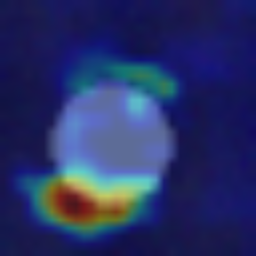

,file,actual,predicted,confidence
5,square_002.png,1,1,0.763
8,triangle_002.png,2,2,0.808
6,triangle_000.png,2,2,0.884
0,circle_000.png,0,0,0.934
1,circle_001.png,0,0,0.950
2,circle_002.png,0,0,0.964
7,triangle_001.png,2,2,0.976
3,square_000.png,1,1,0.986
4,square_001.png,1,1,0.986


In [7]:
# ============================================================
# 5. 예측·CAM 확인
# ============================================================

display(Image(filename=str(OUT / "run1" / "project_cam.png")))
pred1.sort_values("confidence").round(3)

## 6. 2차 실행과 비교 (실습 08)

같은 설정으로 다시 실행하고 CSV·JSON은 바이트로, PNG는 픽셀로 비교한다.

In [8]:
# ============================================================
# 6. 2차 실행과 비교 (실습 08)
# ============================================================

metrics2, history2, pred2, errors2 = run_project(OUT / "run2")
rows = []
for name in ["metrics.csv", "metrics.json", "predictions.csv", "history.csv", "confusion.csv"]:
    same = (OUT / "run1" / name).read_bytes() == (OUT / "run2" / name).read_bytes()
    rows.append({"file": name, "same": same, "method": "bytes"})
a = cv2.imread(str(OUT / "run1" / "project_cam.png"))
b = cv2.imread(str(OUT / "run2" / "project_cam.png"))
rows.append({"file": "project_cam.png", "same": bool(np.array_equal(a, b)), "method": "pixels"})
rerun = pd.DataFrame(rows)
rerun.to_csv(OUT / "p08_rerun_check.csv", index=False)
rerun

{"accuracy": 1.0, "best_epoch": 8, "macro_f1": 1.0, "source": "synthetic_source_pretraining", "test_used": false, "valid_n": 9}
오답 수: 0 예측 행: 9 test 사용: False | CAM 대상: circle_000.png target: circle


,file,same,method
0,metrics.csv,True,bytes
1,metrics.json,True,bytes
2,predictions.csv,True,bytes
3,history.csv,True,bytes
4,confusion.csv,True,bytes
5,project_cam.png,True,pixels


## 7. 실습 08 기록표

| 기록 | 작성 |
|---|---|
| 사용 모델·source 출처 | TinyShapeCNN, 합성 도형 240장 사전학습 Backbone(ImageNet 아님) |
| train/valid 클래스 개수 | train [12, 6, 3], valid [3, 3, 3] |
| 학습 범위·BN 정책 | Head 771개만 학습, BN running 통계 eval 고정 |
| 주 지표와 이유 | Macro F1(train 불균형 때문) |
| 관찰한 오류·CAM target | 최종 모델 오답 0건. 05·06 초기 모델은 오답 4건, CAM target circle |
| 재실행 확인·한계 1개 | 결과 파일 동일. 한계: valid 9장으로 선택·평가를 함께 해 일반화 성능이 아님 |

## 정리

- 최종 모델은 valid Accuracy 1.0, Macro F1 1.0, best_epoch 8, 오답 0건이다. test는 사용하지 않았다.
- 재실행 결과가 같아 설정이 재현된다. 재현을 위해 입력·매핑·source·seed·학습 설정·지표 정책을 고정했다.
- 결과 파일: `outputs_notebook/run1/`, `run2/`, `p08_rerun_check.csv`